<a href="https://colab.research.google.com/github/moushi21/microduck_rl/blob/develop/microduck_run_training_and_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install uv and Clone Repository
- Runtime check: Ensure the Colab runtime is set to NVIDIA L4 GPU (`Runtime` > `Change runtime type` > `L4 GPU`).
- Install `uv` for ultra-fast, reproducible dependency management.
- Clone the `microduck_rl` repository and enter the project directory.

In [ ]:
# Verify GPU environment
!nvidia-smi

!pip install uv
!git clone https://github.com/moushi21/microduck_rl.git
%cd microduck_rl

## 2. Setup Dependencies (PyTorch with CUDA Acceleration)
- Synchronize all project dependencies defined in `pyproject.toml` using `uv sync`.
- Automatically sets up MuJoCo Warp, rsl_rl (PPO), and CUDA-enabled PyTorch.
- Run a quick sanity check to verify that PyTorch detects the NVIDIA L4 GPU.

In [ ]:
!uv pip install --system torch torchvision --index-url https://download.pytorch.org/whl/cu121
!uv pip install --system -e .

## 3. Verify Registered Task:
`Mjlab-Run-Flat-MicroDuck` &

`Mjlab-Run-Flat-Backlash-MicroDuck`
- Inspect the live environment registry using `uv run list-envs`.
- Confirm that the newly implemented `Mjlab-Run-Flat-MicroDuck`&`Mjlab-Run-Flat-Backlash-MicroDuck` task is successfully registered and available for training.

In [ ]:
!uv sync
!uv run list-envs

## 4. Configure WandB via Colab Secrets (Bypassing `wandb-core` Hang)
- Securely fetch the Weights & Biases API key from Colab Secrets (`userdata.get`) to avoid exposing credentials in code.
- Automatically sanitize inputs with `.strip()` to prevent authentication failures caused by invisible trailing spaces.
- **Robust workaround for the `wandb-core` (Go daemon) deadlock**: Bypasses `wandb.login()` entirely by injecting `WANDB_API_KEY` and `WANDB_SILENT` directly into `os.environ`, allowing `rsl_rl` to authenticate seamlessly without freezing.

In [ ]:
from google.colab import userdata
import os
try:
    # 1. Retrieve and sanitize API key
    api_key = userdata.get("WANDB_API_KEY").strip()

    # 2. Inject into environment (bypassing interactive login hang)
    os.environ["WANDB_API_KEY"] = api_key
    os.environ["WANDB_SILENT"] = "true"
    print("✓ Successfully configured WANDB_API_KEY in environment.")

except userdata.SecretNotFoundError:
    print("✗ Error: 'WANDB_API_KEY' is not registered in Colab Secrets (left sidebar 🔑 icon).")

## 5. Smoke Test (5-Iteration Rapid Verification)
- Run a minimal 5-iteration smoke test with 64 parallel environments (`--env.scene.num-envs 64 --agent.max_iterations 5`).
- Catches ~95% of configuration errors, NaN crashes, and tensor mismatches in seconds before launching full-scale training.
- Log in to your Weights & Biases web dashboard and verify that the run is created and streaming metrics (e.g., `Episode_Reward`, loss curves) successfully.

In [ ]:
%env MICRODUCK_WARM_START=0
!uv run train Mjlab-Run-Flat-MicroDuck \
  --env.scene.num-envs 64 \
  --agent.resume False \
  --agent.max_iterations 5

## 6. Full-Scale Run Policy Training (7,000–8,000 Iterations)
- **Training Parameters**: Configured for 8,000 iterations (`--agent.max_iterations 8000`) with 4,096 parallel environments (`--env.scene.num-envs 4096`). The default runner budget in `MicroduckRunRlCfg` is 7,000 iterations (`max_iterations = 7_000`).
- **Estimated Runtime (NVIDIA L4 GPU)**:
  - **Normal Version (`Mjlab-Run-Flat-MicroDuck`)**: Takes approximately **1 hour per 1,000 iterations** (~7 to 8 hours in total for 7,000–8,000 iterations).
  - **Backlash Version (`Mjlab-Run-Flat-Backlash-MicroDuck`)**: Takes **over 1 hour per 1,000 iterations** (~65–75+ minutes per 1,000 iterations, requiring ~8 to 9.5+ hours in total) due to the additional 14 passive backlash hinge DOFs (`passive_*_backlash`) and constraint solver overhead in `robot_walk_backlash.xml`.
- **Minimum Iteration Requirement (7,000+ Iterations)**: Although the final curriculum stage (Stage 4) unlocks at **4,800 iterations**, **a minimum of 7,000 iterations is strictly required** for the policy to consolidate stable high-speed running. The additional ~2,200+ iterations after Stage 4 entry are essential to master the aerial bounding phase, sagittal neck pumping, and straight-line heading hold under full ±8 mm CoM domain randomization.
- **5-Stage Sprint Curriculum (`velocity_command_ranges`)**:
  Instead of training at top speed from scratch (which causes immediate forward falls), `velocity_command_ranges` progressively shifts the forward velocity command window (`lin_vel_x`, with `NUM_STEPS_PER_ENV = 24`) across 5 synchronized stages up to the XL330 hardware limit of **1.25 m/s**:
  1. **Stage 0 (Iter 0–999)**: `0.35 – 0.55 m/s` — Fast stride discovery. Crossing `running_threshold = 0.45 m/s` opens 3D hip (`hip_yaw`, `hip_roll`) and sagittal (`hip_pitch`, `knee`, `ankle`) pose tolerances.
  2. **Stage 1 (Iter 1,000–2,199)**: `0.55 – 0.80 m/s` — Walk-to-run transition and rhythmic sagittal neck pumping (`neck_pitch`).
  3. **Stage 2 (Iter 2,200–3,499)**: `0.75 – 1.00 m/s` — Breaking the ~0.95 m/s single-servo back-EMF speed ceiling via 4-joint serial velocity summation (`hip_pitch + hip_yaw + knee + ankle`) and both-feet-airborne flight phase.
  4. **Stage 3 (Iter 3,500–4,799)**: `0.95 – 1.15 m/s` — High-speed aerial sprint with increased flight-phase reward weight (`2.0`) and full ±8 mm trunk/head CoM randomization.
  5. **Stage 4 (Iter 4,800–8,000)**: `1.05 – 1.25 m/s` — Full hardware-limit sprint (~5.0 body lengths/s, Froude number $\text{Fr} \approx 1.22$), synchronized with maximum `flight_phase` weight (`2.5`) and `action_rate_l2` smoothing (`-0.025`).
- **Colab Anti-Freeze Optimization**: Console stdout is redirected to `/dev/null` (`> /dev/null 2>&1`) to prevent browser tab crashes caused by massive log buffer overflow. Real-time training metrics, reward curves, and loss values are monitored live on the Weights & Biases dashboard.
- **Task Selection**: Choose **either** the **Normal** version or the **Backlash** version below and run the corresponding cell.
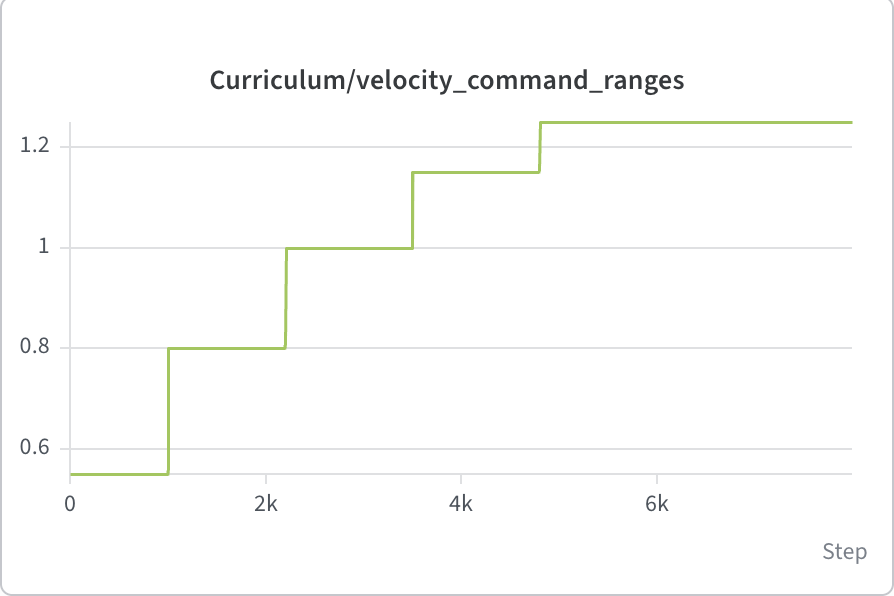

In [ ]:
# [Option A] Normal Version (Mjlab-Run-Flat-MicroDuck)
# Estimated runtime on L4: ~1 hour / 1,000 iter (~7–8 hours for 7,000–8,000 iter)
%env MICRODUCK_WARM_START=0
!uv run train Mjlab-Run-Flat-MicroDuck \
  --env.scene.num-envs 4096 \
  --agent.resume False \
  --agent.max_iterations 8000 > /dev/null 2>&1

In [ ]:
# [Option B] Backlash Version (Mjlab-Run-Flat-Backlash-MicroDuck)
# Estimated runtime on L4: >1 hour / 1,000 iter (~8–9.5+ hours for 7,000–8,000 iter)
%env MICRODUCK_WARM_START=0
!uv run train Mjlab-Run-Flat-Backlash-MicroDuck \
  --env.scene.num-envs 4096 \
  --agent.resume False \
  --agent.max_iterations 8000 > /dev/null 2>&1

## 7. Policy Rollout & Video Rendering (WandB Checkpoint Evaluation)

### Command & Parameter Breakdown
- `xvfb-run --auto-servernum --server-args="-screen 0 1920x1080x24"`: Creates a virtual X11 framebuffer at Full HD (1080p) resolution since Google Colab lacks a physical display, enabling headless offscreen GPU rendering without display-number collisions.
- `uv run play Mjlab-Run-Flat-Backlash-MicroDuck` (or `Mjlab-Run-Flat-MicroDuck`): Specifies the trained Run task environment (Backlash or Normal) to evaluate. In `play` mode, the environment automatically locks the forward velocity command to the constant hardware limit of **`lin_vel_x = 1.25 m/s`** (`vy = 0.0`, `wz = 0.0`) and hides the blue command arrow (`debug_vis = False`).
- `--wandb-run-path <entity/project/run_id>`: Specifies the target WandB run path (e.g., `moushi21-dynasoft-corp-/mjlab_microduck/vmwme2j7`).
- `--num-envs 1`: Spawns a single robot instance to ensure smooth, centered camera tracking (`trunk_base`) during recording.
- `--video True --video-width 1920 --video-height 1080`: Enables Full HD (1920×1080) MP4 video recording for high-fidelity presentation.
- `--video-length 3500`: Total recorded rollout steps. At a 50 Hz control frequency, **3,500 steps yields exactly 70 seconds** of footage ($70\text{ s} = 3500 / 50\text{ Hz}$).
- `--no-terminations True`: **[CRITICAL] Disables standard 20-second (1,000-step) episode timeout resets.** This is essential to rigorously demonstrate that the policy has acquired a stable, continuous high-speed sprint gait at 1.25 m/s (~87.5 m total distance over 70 seconds) without falling or veering.
- `--viewer native`: Leverages the native MuJoCo offscreen renderer.

### Technical Notes on Inference & Rendering
- **61D Shared Observation Space**: Executes closed-loop policy inference feeding the exact 61-dimensional observation vector (48D proprioception + 13D command block) required for physical hardware deployment. On the Backlash variant, joint positions and velocities are read through the ±1° passive backlash encoder view (`joint_pos_rel_backlash` / `joint_vel_rel_backlash`).
- **Rendering Duration**: High-quality 1080p offscreen rendering for 3,500 frames takes approximately **45 to 60 minutes** on an L4 GPU. Please wait for the process to complete.
- **Output Video Location**: The rendered `.mp4` video will be saved under the `logs/rsl_rl/run/.../videos/` directory. You can download and preview it directly from Colab's left sidebar file explorer (📁 icon).

In [ ]:
import os

# Configure GPU offscreen rendering backends (EGL)
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

# Execute headless rollout and video rendering using xvfb-run and native viewer
!xvfb-run --auto-servernum --server-args="-screen 0 1920x1080x24" \
    uv run play Mjlab-Run-Flat-Backlash-MicroDuck \
    --wandb-run-path moushi21-dynasoft-corp-/mjlab_microduck/vmwme2j7 \
    --num-envs 1 \
    --video True \
    --video-width 1920 \
    --video-height 1080 \
    --video-length 3500 \
    --no-terminations True \
    --viewer native

## 8. Playback the Rendered Video & High-Speed Sprint Gait Analysis
- Play the generated 70-second (3,500-step) rollout video directly inside the notebook.
- **Notice**: The output destination of the `.mp4` file may vary depending on the task configuration and WandB run ID. Please check the `logs/rsl_rl/run/` directory, set the appropriate `video_path` (Normal or Backlash), and then play the video.

### Key Biomechanical Highlights Observed in the 1.25 m/s Rollout
1. **Breaking the Single-Servo Speed Ceiling via 4-Joint Serial Summation & Flight Phase**
   - A single Dynamixel XL330 servo is limited by back-EMF to an unloaded foot swing speed of ~0.95 m/s. To sustain **1.25 m/s (~5.0 body lengths/s, Froude number $\text{Fr} \approx 1.22$)**, the policy coordinates 4-joint serial velocity summation (`hip_pitch + hip_yaw + knee + ankle`) at push-off, combined with a **ballistic aerial flight phase** (both feet simultaneously airborne) and high 3.5 cm swing-knee folding to minimize leg rotational inertia ($I = m r^2$).
2. **Horizontal Trunk Posture & Dynamic Sagittal Neck Pumping**
   - The trunk remains nearly horizontal to the ground (`TARGET_FORWARD_LEAN_RAD = 0.08 rad` $\approx 4.6^\circ$) so the hip joints stay high and retain 100% of their forward swing range.
   - To counterbalance the heavy rear `NP-F970` battery without pitching the trunk nose-down into the thighs, the neck extends forward (`SPRINT_HEAD_OFFSET = (-1.55, -1.45, 0.0, 0.0)`), shifting the **280 g head CoM ~4.7 cm forward** while `neck_pitch` pumps rhythmically in the sagittal plane in phase with leg kicks and `head_pitch` keeps the face slightly nose-down (~5.7°) without tucking under.
3. **Robustness Against ±1.0° Serial Gear Backlash (`Mjlab-Run-Flat-Backlash-MicroDuck`)**
   - Even with 14 unactuated ±1.0° backlash hinges (`passive_*_backlash`) inserted in series across the legs and neck—and observing joint states strictly through the backlash encoder view (`joint_pos_rel_backlash` / `joint_vel_rel_backlash`)—the policy maintains straight-line heading hold (`heading_hold_reward`) and bilateral stride symmetry (`gait_symmetry_penalty`) over the entire 70-second endurance rollout without chattering or stumbling.

In [ ]:
import os
from IPython.display import HTML
from base64 import b64encode

# Exact file path to the rendered rollout video
# Normal Version (Mjlab-Run-Flat-MicroDuck)
# video_path = "logs/rsl_rl/run/wandb_checkpoints/pmbpeqmr/videos/play/rl-video-step-0.mp4"

# Backlash Version (Mjlab-Run-Flat-Backlash-MicroDuck)
video_path = "logs/rsl_rl/run/wandb_checkpoints/vmwme2j7/videos/play/rl-video-step-0.mp4"

if os.path.exists(video_path):
    print(f"Loading Video: {video_path}")
    mp4_data = b64encode(open(video_path, 'rb').read()).decode()
    display(HTML(f'<video width="640" height="480" controls><source src="data:video/mp4;base64,{mp4_data}" type="video/mp4"></video>'))
else:
    print(f"Video file not found. Please verify that the rendering cell completed successfully. Path: {video_path}")